# Predicting Credit Card Fraud
## Score: .94980


## EDA


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from scipy import sparse as sp
from xgboost import XGBClassifier
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.preprocessing import OneHotEncoder

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")
y = train["is_fraud"].astype(int)

cat_cols = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
bool_cols = [
    "is_foreign_transaction",
    "is_new_merchant",
    "used_vpn",
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt",
]
num_cols = [
    c
    for c in train.columns
    if c not in cat_cols + bool_cols + ["id", "is_fraud"]
]
digit_num_cols = [
    "amount_usd",
    "hours_since_last_txn",
    "distance_from_home_km",
    "account_balance_usd",
    "velocity_score",
    "merchant_risk_score",
]

In [2]:
display(pd.DataFrame({
    "split": ["train", "test"],
    "rows": [len(train), len(test)],
    "cols": [train.shape[1], test.shape[1]],
    "nulls": [train.isna().sum().sum(), test.isna().sum().sum()],
    "dup_ids": [train["id"].duplicated().sum(), test["id"].duplicated().sum()],
}))
display(train.dtypes.to_frame("dtype"))
display(train[num_cols + ["is_fraud"]].describe().T)

,split,rows,cols,nulls,dup_ids
0,train,699960,26,0,0
1,test,299984,25,0,0


,dtype
id,int64
amount_usd,float64
hours_since_last_txn,float64
txn_count_last_24h,int64
distance_from_home_km,float64
card_age_months,int64
customer_age,int64
account_balance_usd,float64
cvv_retry_count,int64
velocity_score,float64


,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,699960.0,11.761915,6.869164,0.00,6.00,12.00,18.00,23.00


,count,rate
is_fraud,,
0.0,688271,0.9833
1.0,11689,0.0167


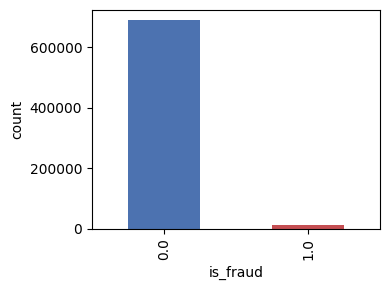

In [3]:
target_counts = train["is_fraud"].value_counts().rename("count")
target_rate = train["is_fraud"].value_counts(normalize=True).rename("rate")
display(pd.concat([target_counts, target_rate], axis=1))

fig, ax = plt.subplots(figsize=(4, 3))
train["is_fraud"].value_counts().plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_xlabel("is_fraud")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

,feature,fraud_rate,count
merchant_category,,,
Gift Cards,merchant_category,0.072970,9456
Crypto Exchange,merchant_category,0.065279,5285
Gaming,merchant_category,0.055121,23784
Electronics,merchant_category,0.030826,48693
Streaming,merchant_category,0.022481,47196
Travel,merchant_category,0.018597,28715
Utilities,merchant_category,0.013824,42027
Healthcare,merchant_category,0.012873,35889
Fuel,merchant_category,0.012375,59880


,feature,fraud_rate,count
card_type,,,
Amex,card_type,0.019019,45797
Visa,card_type,0.016985,345001
RuPay,card_type,0.016806,37070
Mastercard,card_type,0.016025,254857
Discover,card_type,0.014563,17235


,feature,fraud_rate,count
auth_method,,,
No Authentication,auth_method,0.064450,67060
3D Secure,auth_method,0.014750,210036
OTP,auth_method,0.014066,175178
PIN,auth_method,0.008681,154020
Biometric,auth_method,0.004996,93666


,feature,fraud_rate,count
channel,,,
Online,channel,0.017424,273939
POS,channel,0.016603,206465
In-App,channel,0.016329,83716
ATM,channel,0.015884,30220
Contactless,channel,0.015537,105620


,feature,fraud_rate,count
device_type,,,
POS Terminal,device_type,0.017291,113237
iPhone,device_type,0.017220,164691
Mac,device_type,0.017102,33973
Tablet,device_type,0.017011,27688
Smart Watch,device_type,0.017009,21106
ATM Machine,device_type,0.016956,20877
Windows PC,device_type,0.016137,80934
Android Phone,device_type,0.016104,237454


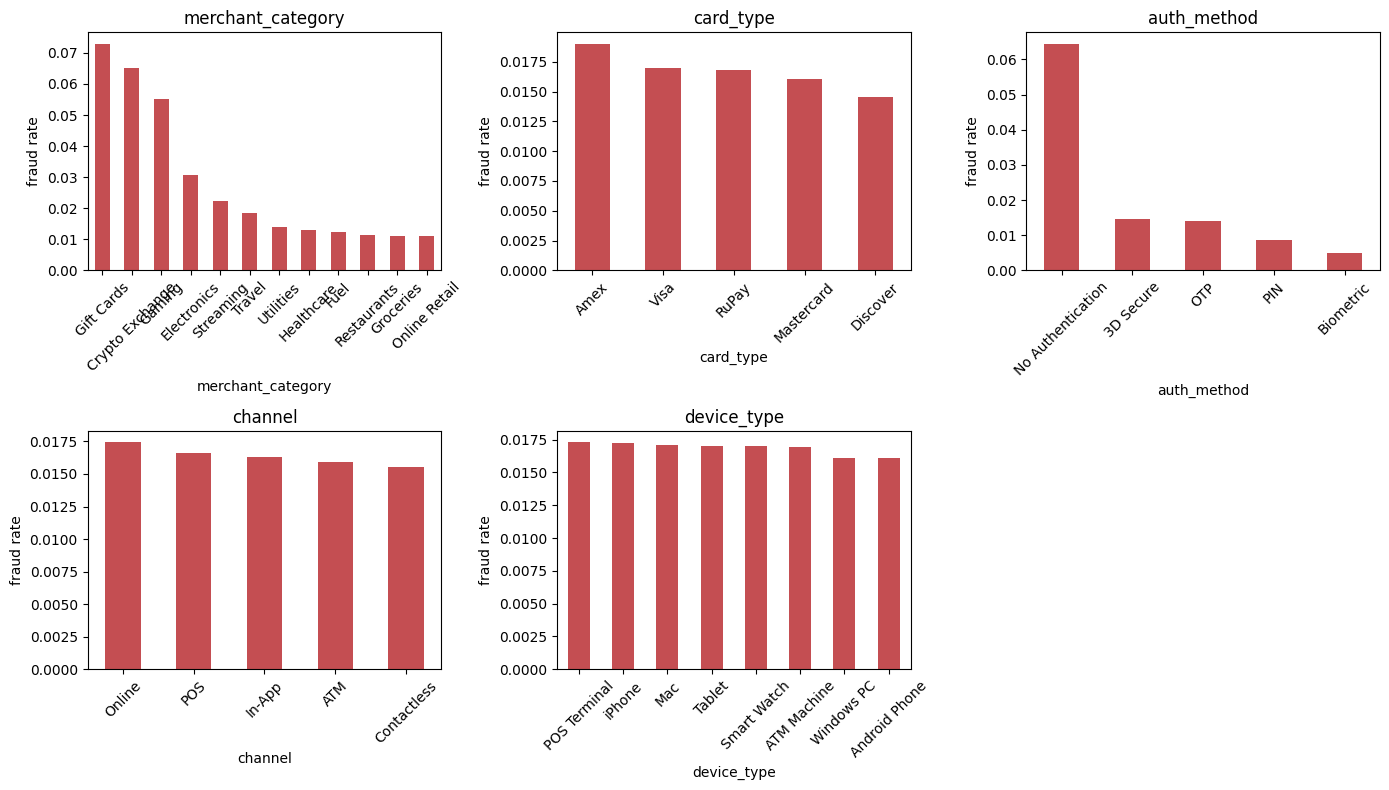

In [4]:
fraud_by_cat = []
for col in cat_cols:
    g = (
        train.groupby(col)["is_fraud"]
        .agg(fraud_rate="mean", count="size")
        .sort_values("fraud_rate", ascending=False)
    )
    g.insert(0, "feature", col)
    fraud_by_cat.append(g)
    display(g)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, col in enumerate(cat_cols):
    rates = train.groupby(col)["is_fraud"].mean().sort_values(ascending=False)
    rates.plot(kind="bar", ax=axes[i], color="#C44E52")
    axes[i].set_title(col)
    axes[i].set_ylabel("fraud rate")
    axes[i].tick_params(axis="x", rotation=45)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

,feature,fraud_rate,count
False,is_foreign_transaction,0.014782,687862
True,is_foreign_transaction,0.125723,12098
False,is_new_merchant,0.011188,593240
True,is_new_merchant,0.047339,106720
False,used_vpn,0.014992,676295
True,used_vpn,0.065498,23665
False,ip_country_mismatch,0.014264,688648
True,ip_country_mismatch,0.164958,11312
False,billing_shipping_mismatch,0.015216,690906
True,billing_shipping_mismatch,0.129887,9054


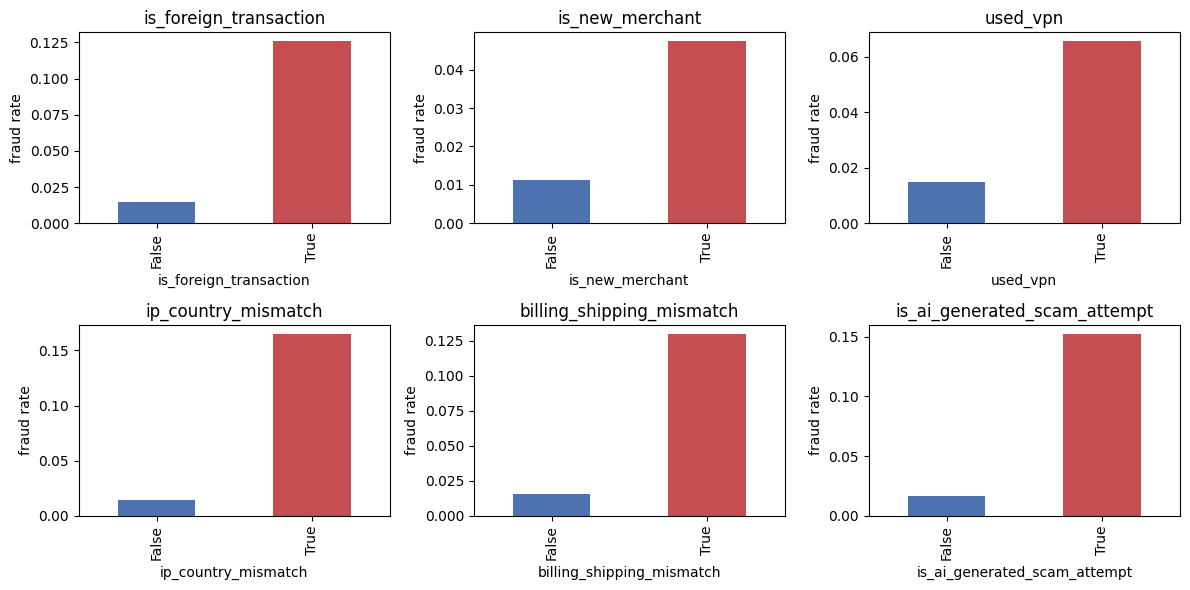

In [5]:
bool_stats = []
for col in bool_cols:
    g = train.groupby(col)["is_fraud"].agg(fraud_rate="mean", count="size")
    g.insert(0, "feature", col)
    bool_stats.append(g)
display(pd.concat(bool_stats))

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.ravel()
for i, col in enumerate(bool_cols):
    rates = train.groupby(col)["is_fraud"].mean()
    rates.plot(kind="bar", ax=axes[i], color=["#4C72B0", "#C44E52"])
    axes[i].set_title(col)
    axes[i].set_ylabel("fraud rate")
plt.tight_layout()
plt.show()

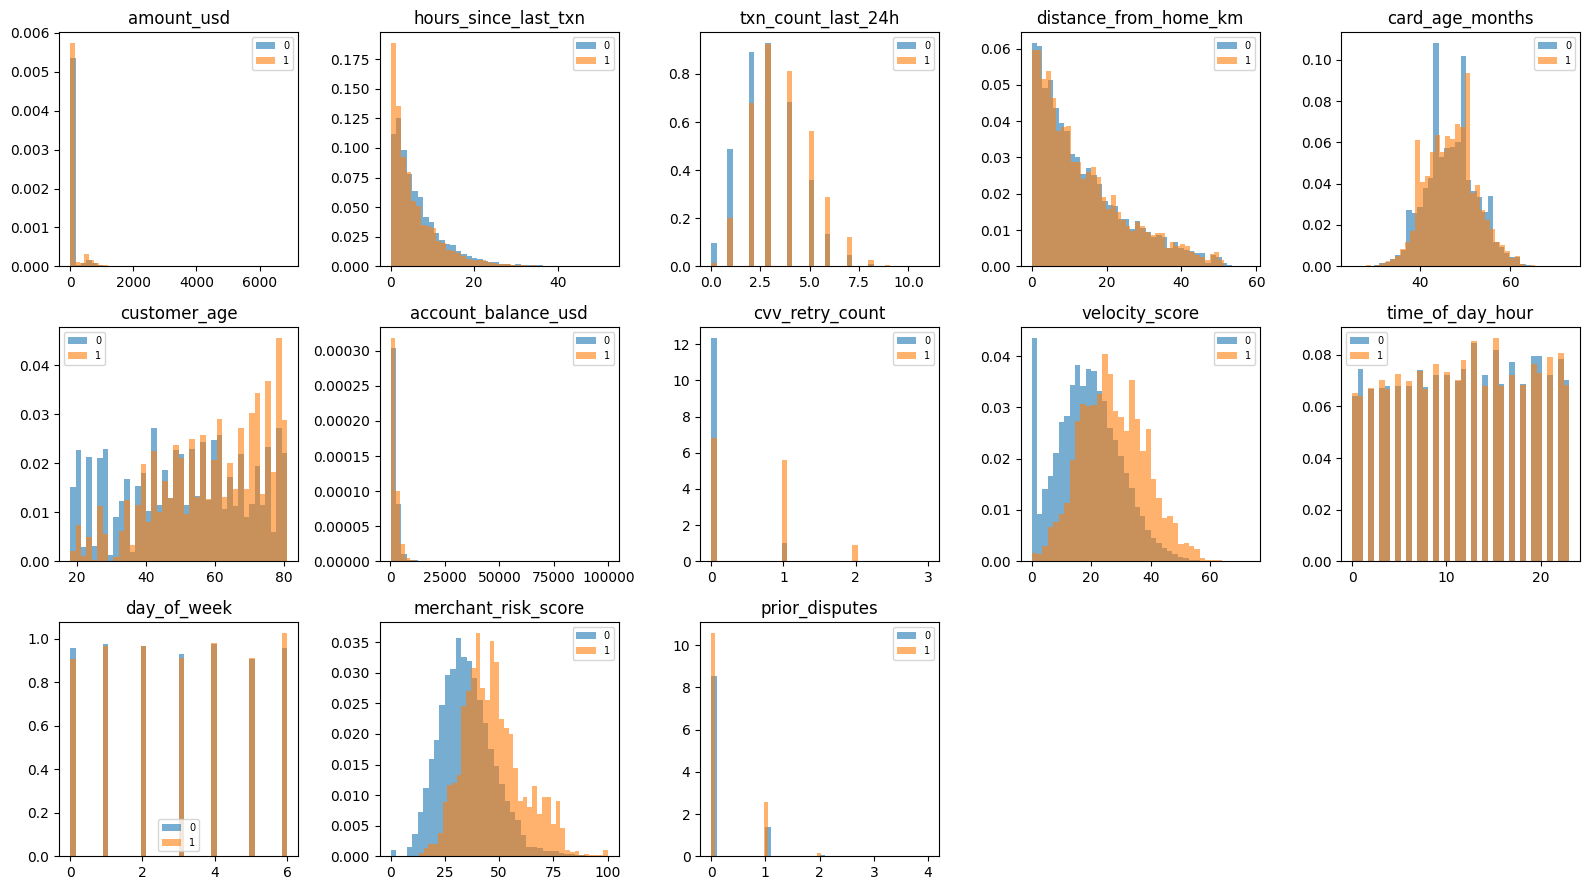

is_fraud,legit,fraud
cvv_retry_count,,
0,0.990671,0.009329
1,0.912499,0.087501
2,0.582677,0.417323
3,0.640000,0.360000


In [6]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
axes = axes.ravel()
for i, col in enumerate(num_cols):
    axes[i].hist(train.loc[train["is_fraud"] == 0, col], bins=40, alpha=0.6, density=True, label="0")
    axes[i].hist(train.loc[train["is_fraud"] == 1, col], bins=40, alpha=0.6, density=True, label="1")
    axes[i].set_title(col)
    axes[i].legend(fontsize=7)
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

display(
    pd.crosstab(train["cvv_retry_count"], train["is_fraud"], normalize="index")
    .rename(columns={0.0: "legit", 1.0: "fraud"})
)

In [7]:
shift_rows = []
for col in num_cols + bool_cols:
    shift_rows.append({
        "feature": col,
        "train_mean": train[col].astype(float).mean(),
        "test_mean": test[col].astype(float).mean(),
    })
shift = pd.DataFrame(shift_rows)
shift["rel_diff_pct"] = (
    (shift["test_mean"] - shift["train_mean"]) / (shift["train_mean"].abs() + 1e-9) * 100
)
display(shift.sort_values("rel_diff_pct", key=np.abs, ascending=False))

,feature,train_mean,test_mean,rel_diff_pct
18,is_ai_generated_scam_attempt,0.003284,0.003430,4.436312
15,used_vpn,0.033809,0.032968,-2.486462
17,billing_shipping_mismatch,0.012935,0.013087,1.177731
16,ip_country_mismatch,0.016161,0.016034,-0.784206
12,prior_disputes,0.152769,0.153922,0.754613
13,is_foreign_transaction,0.017284,0.017394,0.638841
10,day_of_week,2.981733,2.971338,-0.348615
6,account_balance_usd,2064.998070,2071.467998,0.313314
14,is_new_merchant,0.152466,0.152828,0.237624
9,time_of_day_hour,11.761915,11.746940,-0.127319


,corr_with_is_fraud
cvv_retry_count,0.212290
ip_country_mismatch,0.148284
merchant_risk_score,0.125391
is_foreign_transaction,0.112832
velocity_score,0.101650
is_new_merchant,0.101412
billing_shipping_mismatch,0.101115
used_vpn,0.071235
is_ai_generated_scam_attempt,0.060719
txn_count_last_24h,0.058035


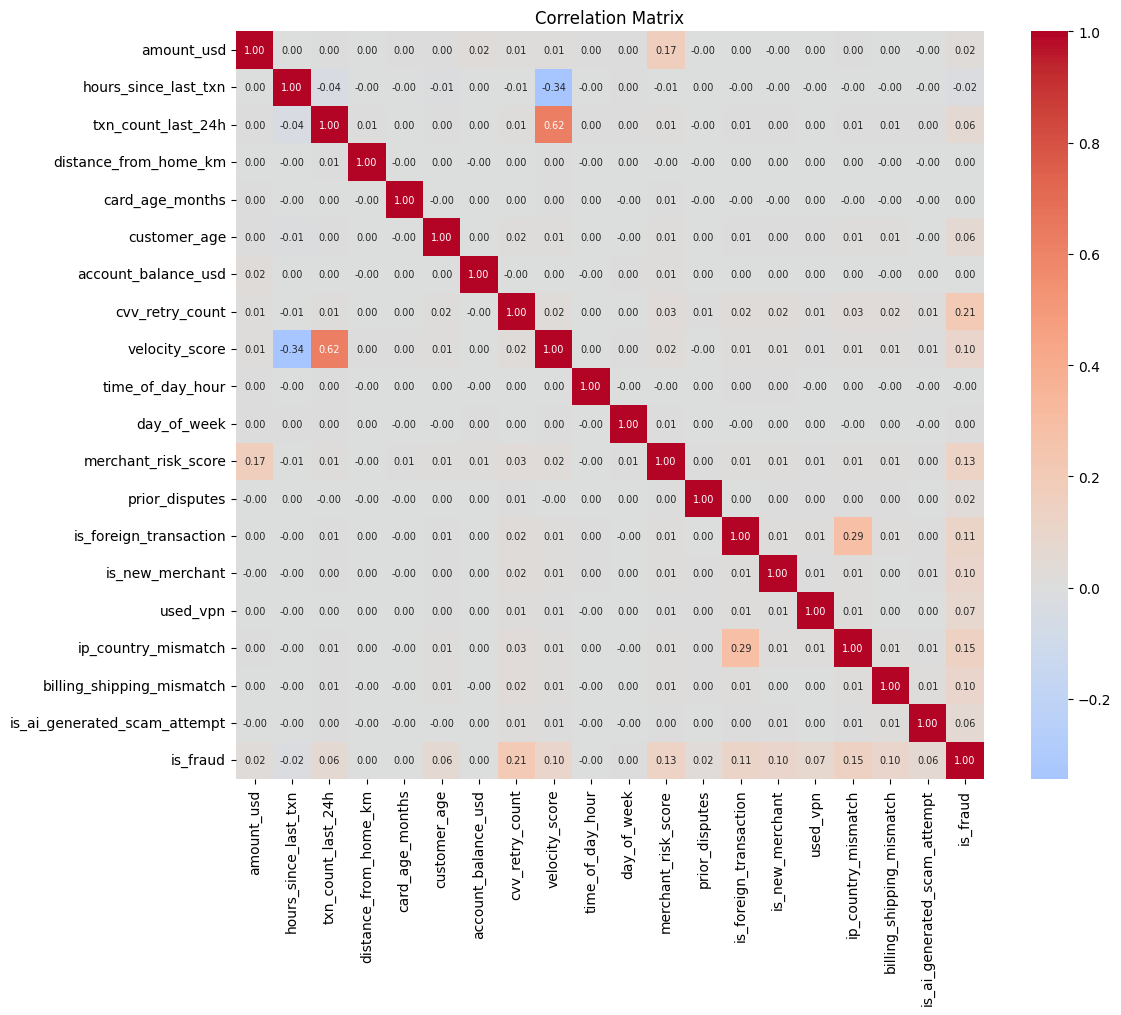

In [8]:
corr_df = train.copy()
for col in bool_cols:
    corr_df[col] = corr_df[col].astype(int)

corr_features = num_cols + bool_cols + ["is_fraud"]
corr = corr_df[corr_features].corr()

display(
    corr["is_fraud"]
    .drop("is_fraud")
    .sort_values(key=np.abs, ascending=False)
    .to_frame("corr_with_is_fraud")
)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    square=True,
    ax=ax,
)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

## Feature Engineering (v2)

New angles vs prior plateau (~0.9507):
1. **Clean digit artifacts** — parity / grid-distance / frac bins instead of only dumping dig1..dig7
2. **Targeted interactions** — risk-cap≥80, cvv×auth, merchant×riskbin, velocity×txn24
3. **Fold-local nested TE** — TE fit only on outer-fold train rows (honest CV)
4. **Stump offset → residual boost** — depth-1 additive prior, then trees correct leftovers via `init_score` / `base_margin`
5. **Monotone constraints** on risk / velocity / cvv / disputes
6. **CatBoost ordered cats** — native categoricals, no precomputed TE


In [9]:
def add_digit_features(df, cols):
    out = df.copy()
    for col in cols:
        vals = out[col].astype(float)
        frac = vals - np.floor(vals)
        out[f"{col}_frac"] = frac
        out[f"{col}_int"] = np.floor(vals).astype(np.int32)
        abs_vals = np.maximum(np.abs(vals), 1e-12)
        out[f"{col}_lead"] = (abs_vals / np.power(10, np.floor(np.log10(abs_vals)))).astype(np.int8)
        dig_sum = np.zeros(len(out), dtype=np.int16)
        for k in range(1, 7):
            dig = ((vals * (10 ** k)) % 10).astype(np.int8)
            out[f"{col}_dig{k}"] = dig
            dig_sum = dig_sum + dig
        out[f"{col}_digsum"] = dig_sum
        out[f"{col}_pair12"] = out[f"{col}_dig1"] * 10 + out[f"{col}_dig2"]
        out[f"{col}_pair23"] = out[f"{col}_dig2"] * 10 + out[f"{col}_dig3"]
        out[f"{col}_id1"] = np.round(vals * 10).astype(np.int32)
        out[f"{col}_id2"] = np.round(vals * 100).astype(np.int32)
        out[f"{col}_id3"] = np.round(vals * 1000).astype(np.int32)
        for k in range(0, 4):
            out[f"{col}_round{k}"] = vals.round(k)

        # Clean generator-artifact features (new)
        out[f"{col}_parity_d1"] = (out[f"{col}_dig1"] % 2).astype(np.int8)
        out[f"{col}_parity_d2"] = (out[f"{col}_dig2"] % 2).astype(np.int8)
        out[f"{col}_parity_sum"] = (dig_sum % 2).astype(np.int8)
        out[f"{col}_dist05"] = np.minimum(frac % 0.05, 0.05 - (frac % 0.05)).astype(np.float32)
        out[f"{col}_dist01"] = np.minimum(frac % 0.01, 0.01 - (frac % 0.01)).astype(np.float32)
        out[f"{col}_frac20"] = np.round(frac * 20).astype(np.int8)
    return out


def add_frequency_features(train_df, test_df, cols):
    tr = train_df.copy()
    te = test_df.copy()
    for col in cols:
        freq_tr = train_df[col].value_counts()
        freq_all = pd.concat([train_df[col], test_df[col]], axis=0).value_counts()
        tr[f"{col}_freq"] = train_df[col].map(freq_tr).astype(np.float32)
        te[f"{col}_freq"] = test_df[col].map(freq_tr).fillna(1).astype(np.float32)
        tr[f"{col}_freq_all"] = train_df[col].map(freq_all).astype(np.float32)
        te[f"{col}_freq_all"] = test_df[col].map(freq_all).astype(np.float32)
        tr[f"{col}_rare"] = (tr[f"{col}_freq"] <= 5).astype(np.int8)
        te[f"{col}_rare"] = (te[f"{col}_freq"] <= 5).astype(np.int8)
    return tr, te


def add_value_codes(train_df, test_df, cols):
    tr = train_df.copy()
    te = test_df.copy()
    for col in cols:
        combined = pd.concat([train_df[col], test_df[col]], axis=0)
        codes, _ = pd.factorize(combined, sort=True)
        tr[f"{col}_vcode"] = codes[: len(train_df)].astype(np.int32)
        te[f"{col}_vcode"] = codes[len(train_df) :].astype(np.int32)
    return tr, te


def encode_base(df, cat_maps=None):
    out = df.drop(columns=["id", "is_fraud"], errors="ignore").copy()
    for col in bool_cols:
        out[col] = out[col].astype(np.int8)
    maps = {}
    for col in cat_cols:
        if cat_maps is None:
            cats = sorted(out[col].astype(str).unique())
            maps[col] = {v: i for i, v in enumerate(cats)}
        else:
            maps[col] = cat_maps[col]
        out[col] = out[col].astype(str).map(maps[col]).fillna(-1).astype(np.int16)
    return out, maps


def add_interaction_features(df):
    out = df.copy()
    risk = out["merchant_risk_score"].astype(float)
    out["risk_cap80"] = (risk >= 80).astype(np.int8)
    out["risk_gt80_gap"] = np.maximum(risk - 80.0, 0.0).astype(np.float32)
    out["risk_lt80"] = np.minimum(risk, 80.0).astype(np.float32)
    out["risk_bin10"] = (np.floor(np.clip(risk, 0, 99) / 10)).astype(np.int8)
    out["flag_sum"] = (
        out[bool_cols].sum(axis=1).astype(np.int8)
        if set(bool_cols).issubset(out.columns)
        else 0
    )
    out["cvv_x_auth"] = (out["cvv_retry_count"].astype(np.int16) * 16 + out["auth_method"].astype(np.int16)).astype(np.int16)
    out["mcat_x_riskbin"] = (out["merchant_category"].astype(np.int16) * 20 + out["risk_bin10"].astype(np.int16)).astype(np.int16)
    out["vel_x_txn24"] = (out["velocity_score"].astype(float) * out["txn_count_last_24h"].astype(float)).astype(np.float32)
    out["bal_x_amt"] = (out["account_balance_usd"].astype(float) / (out["amount_usd"].astype(float) + 1.0)).astype(np.float32)
    out["dist_x_foreign"] = (out["distance_from_home_km"].astype(float) * out["is_foreign_transaction"].astype(float)).astype(np.float32)
    out["hour_sin"] = np.sin(2 * np.pi * out["time_of_day_hour"] / 24).astype(np.float32)
    out["hour_cos"] = np.cos(2 * np.pi * out["time_of_day_hour"] / 24).astype(np.float32)
    out["dow_sin"] = np.sin(2 * np.pi * out["day_of_week"] / 7).astype(np.float32)
    out["dow_cos"] = np.cos(2 * np.pi * out["day_of_week"] / 7).astype(np.float32)
    return out


def te_map(values, y_arr, smooth, global_mean):
    stats = (
        pd.DataFrame({"y": y_arr, "v": values})
        .groupby("v")["y"]
        .agg(["mean", "count"])
    )
    mapping = (
        (stats["mean"] * stats["count"] + global_mean * smooth) / (stats["count"] + smooth)
    ).to_dict()
    return mapping


def apply_te(series, mapping, global_mean):
    return series.map(mapping).fillna(global_mean).astype(np.float32)


def add_oof_target_encoding(train_df, test_df, y_arr, cols, n_splits=5, smooth=20, seed=42):
    """Global OOF TE used for base feature matrix / GLM keys."""
    tr = train_df.copy()
    te = test_df.copy()
    global_mean = float(y_arr.mean())
    skf_te = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for col in cols:
        oof = np.full(len(tr), global_mean, dtype=np.float32)
        for tr_idx, va_idx in skf_te.split(train_df, y_arr):
            mapping = te_map(train_df.iloc[tr_idx][col].values, y_arr[tr_idx], smooth, global_mean)
            oof[va_idx] = apply_te(train_df.iloc[va_idx][col], mapping, global_mean).values
        tr[f"{col}_te"] = oof
        mapping = te_map(train_df[col].values, y_arr, smooth, global_mean)
        te[f"{col}_te"] = apply_te(test_df[col], mapping, global_mean)
    return tr, te


def fold_target_encode(train_df, test_df, y_arr, tr_idx, va_idx, cols, smooth=20):
    """Nested TE: fit on outer-fold train only; transform va + test."""
    global_mean = float(y_arr[tr_idx].mean())
    tr_te = {}
    va_te = {}
    te_te = {}
    for col in cols:
        mapping = te_map(train_df.iloc[tr_idx][col].values, y_arr[tr_idx], smooth, global_mean)
        # leave-one-out-ish via inner OOF on tr_idx only for train rows
        inner = np.full(len(tr_idx), global_mean, dtype=np.float32)
        skf_in = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        y_tr = y_arr[tr_idx]
        for i_tr, i_va in skf_in.split(np.zeros(len(tr_idx)), y_tr):
            map_i = te_map(
                train_df.iloc[tr_idx[i_tr]][col].values,
                y_tr[i_tr],
                smooth,
                global_mean,
            )
            inner[i_va] = apply_te(train_df.iloc[tr_idx[i_va]][col], map_i, global_mean).values
        tr_te[f"{col}_te"] = inner
        va_te[f"{col}_te"] = apply_te(train_df.iloc[va_idx][col], mapping, global_mean).values
        te_te[f"{col}_te"] = apply_te(test_df[col], mapping, global_mean).values
    return tr_te, va_te, te_te


X_raw, cat_maps = encode_base(train)
X_test_raw, _ = encode_base(test, cat_maps=cat_maps)
X_raw = add_digit_features(X_raw, digit_num_cols)
X_test_raw = add_digit_features(X_test_raw, digit_num_cols)
X_raw, X_test_raw = add_frequency_features(X_raw, X_test_raw, digit_num_cols)
X_raw, X_test_raw = add_value_codes(X_raw, X_test_raw, digit_num_cols)
X_raw = add_interaction_features(X_raw)
X_test_raw = add_interaction_features(X_test_raw)

te_cols = (
    cat_cols
    + [f"{c}_id2" for c in digit_num_cols]
    + [f"{c}_pair12" for c in digit_num_cols]
    + [f"{c}_vcode" for c in digit_num_cols]
    + ["cvv_x_auth", "mcat_x_riskbin"]
)

# Global OOF TE kept for GLM / reference models
X, X_test = add_oof_target_encoding(X_raw, X_test_raw, y.values, te_cols, smooth=20, seed=42)

feature_cols = [c for c in X.columns if c in X_test.columns]
X = X[feature_cols].copy()
X_test = X_test[feature_cols].copy()
X_raw = X_raw.copy()
X_test_raw = X_test_raw.copy()

mono_up = ["merchant_risk_score", "velocity_score", "cvv_retry_count", "prior_disputes", "risk_lt80", "flag_sum"]
mono_constraints = [1 if c in mono_up else 0 for c in feature_cols]

display(pd.Series({
    "n_features": len(feature_cols),
    "n_te_cols": len(te_cols),
    "n_mono": sum(mono_constraints),
}))
display(X[[c for c in X.columns if c.endswith("_dist05") or c.endswith("_parity_d1") or c in ["risk_cap80", "cvv_x_auth"]]].head())

C:\Users\ol1v3_7dwns5u\AppData\Local\Temp\ipykernel_4600\1282444737.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{col}_parity_sum"] = (dig_sum % 2).astype(np.int8)
C:\Users\ol1v3_7dwns5u\AppData\Local\Temp\ipykernel_4600\1282444737.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{col}_dist05"] = np.minimum(frac % 0.05, 0.05 - (frac % 0.05)).astype(np.float32)
C:\Users\ol1v3_7dwns5u\AppData\Local\Temp\ipykernel_4600\1282444737.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the

n_features    237
n_te_cols      25
n_mono          6
dtype: int64

,amount_usd_parity_d1,amount_usd_dist05,hours_since_last_txn_parity_d1,hours_since_last_txn_dist05,distance_from_home_km_parity_d1,distance_from_home_km_dist05,account_balance_usd_parity_d1,account_balance_usd_dist05,velocity_score_parity_d1,velocity_score_dist05,merchant_risk_score_parity_d1,merchant_risk_score_dist05,risk_cap80,cvv_x_auth
0,1,1.000000e-02,1,2.000000e-02,1,0.02,1,9.096890e-14,1,2.775558e-17,0,7.216450e-16,0,3
1,0,2.000000e-02,1,1.000000e-02,0,0.01,0,0.000000e+00,0,1.443290e-15,1,1.471046e-15,0,4
2,1,1.000000e-02,0,5.551115e-17,1,0.02,0,2.000000e-02,0,2.886580e-15,1,1.415534e-15,0,3
3,0,1.000000e-02,1,2.000000e-02,0,0.02,0,2.000000e-02,1,7.494005e-16,1,1.471046e-15,0,0
4,0,2.269018e-14,0,0.000000e+00,0,0.01,0,1.000000e-02,0,2.886580e-15,0,0.000000e+00,0,0


## Model (v2) — GLM offset residual boost + monotone + ordered CatBoost


In [10]:
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def make_key_frame(df):
    parts = {}
    for col in digit_num_cols:
        parts[f"v_{col}"] = col + "=" + df[col].astype(str)
        parts[f"vc_{col}"] = f"{col}_vcode=" + df[f"{col}_vcode"].astype(str)
        parts[f"id2_{col}"] = f"{col}_id2=" + df[f"{col}_id2"].astype(str)
        parts[f"p12_{col}"] = f"{col}_pair12=" + df[f"{col}_pair12"].astype(str)
        parts[f"par1_{col}"] = f"{col}_par1=" + df[f"{col}_parity_d1"].astype(str)
        parts[f"f20_{col}"] = f"{col}_f20=" + df[f"{col}_frac20"].astype(str)
        for k in range(1, 4):
            parts[f"d{k}_{col}"] = f"{col}_dig{k}=" + df[f"{col}_dig{k}"].astype(str)
    for col in cat_cols:
        parts[f"c_{col}"] = col + "=" + df[col].astype(str)
    parts["cvv_auth"] = "cvv_auth=" + df["cvv_x_auth"].astype(str)
    parts["mcat_risk"] = "mcat_risk=" + df["mcat_x_riskbin"].astype(str)
    parts["risk_cap"] = "risk_cap=" + df["risk_cap80"].astype(str)
    return pd.DataFrame(parts)


def fit_lgb(
    X_tr,
    y_tr,
    X_va,
    y_va,
    seed,
    num_leaves,
    max_depth,
    lr,
    cols,
    n_estimators=12000,
    stop=300,
    monotone=None,
    init_score_tr=None,
    init_score_va=None,
):
    params = dict(
        objective="binary",
        metric="auc",
        learning_rate=lr,
        num_leaves=num_leaves,
        max_depth=max_depth,
        min_child_samples=40,
        subsample=0.85,
        colsample_bytree=0.7,
        reg_lambda=1.0,
        reg_alpha=0.0,
        n_estimators=n_estimators,
        random_state=seed,
        n_jobs=4,
        verbose=-1,
    )
    if monotone is not None:
        params["monotone_constraints"] = monotone
    model = lgb.LGBMClassifier(**params)
    fit_kwargs = dict(
        eval_set=[(X_va[cols], y_va)],
        callbacks=[lgb.early_stopping(stop, verbose=False)],
    )
    if init_score_tr is not None:
        fit_kwargs["init_score"] = init_score_tr
        fit_kwargs["eval_init_score"] = [init_score_va]
    model.fit(X_tr[cols], y_tr, **fit_kwargs)
    return model


def apply_te_override(base_df, te_dict):
    out = base_df.copy()
    for col, vals in te_dict.items():
        out[col] = vals
    return out


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = {}
test_preds = {}
train_key_df = make_key_frame(X)
test_key_df = make_key_frame(X_test)
te_logit_cols = [f"{c}_te" for c in te_cols]

# Precompute nested TE once per outer fold (shared by all tree models)
fold_data = []
print("precomputing nested TE per fold...")
for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
    tr_te, va_te, te_te = fold_target_encode(
        X_raw, X_test_raw, y.values, tr_idx, va_idx, te_cols, smooth=20
    )
    X_tr = apply_te_override(X.iloc[tr_idx], tr_te)
    X_va = apply_te_override(X.iloc[va_idx], va_te)
    X_te = apply_te_override(X_test, te_te)
    fold_data.append({
        "fold": fold,
        "tr_idx": tr_idx,
        "va_idx": va_idx,
        "X_tr": X_tr,
        "X_va": X_va,
        "X_te": X_te,
    })
    print(f"  fold {fold} ready")

print("features", len(feature_cols), "keys", train_key_df.shape[1], "te", len(te_logit_cols))


precomputing nested TE per fold...
  fold 1 ready
  fold 2 ready
  fold 3 ready
  fold 4 ready
  fold 5 ready
features 237 keys 62 te 25


In [11]:
# 1) Additive stump base (depth-1 LGB) — strong near-linear prior for residual boosting
# Stumps already land near ~0.948 here; residual trees then fix structured mistakes.
oof_base = np.zeros(len(X))
pred_base = np.zeros(len(X_test))
oof_glm_logit = np.zeros(len(X))  # name reused by offset cells
pred_glm_logit = np.zeros(len(X_test))

for fd in fold_data:
    fold, tr_idx, va_idx = fd["fold"], fd["tr_idx"], fd["va_idx"]
    X_tr, X_va, X_te = fd["X_tr"], fd["X_va"], fd["X_te"]
    model = fit_lgb(
        X_tr, y.iloc[tr_idx], X_va, y.iloc[va_idx],
        seed=100 + fold,
        num_leaves=2,
        max_depth=1,
        lr=0.03,
        cols=feature_cols,
        stop=400,
    )
    p_va = model.predict_proba(X_va[feature_cols])[:, 1]
    p_te = model.predict_proba(X_te[feature_cols])[:, 1]
    oof_base[va_idx] = p_va
    pred_base += p_te / skf.n_splits
    oof_glm_logit[va_idx] = logit(p_va)
    pred_glm_logit += logit(p_te) / skf.n_splits
    print(f"stump fold {fold}: {roc_auc_score(y.iloc[va_idx], p_va):.6f} iter={model.best_iteration_}")

print(f"stump cv: {roc_auc_score(y, oof_base):.6f}")
oof_preds["lgb_stump"] = oof_base
test_preds["lgb_stump"] = pred_base


stump fold 1: 0.947684 iter=11427
stump fold 2: 0.949160 iter=11895
stump fold 3: 0.953507 iter=11982
stump fold 4: 0.949240 iter=11272
stump fold 5: 0.943777 iter=11952
stump cv: 0.948649


In [12]:
# 2) LightGBM residual boost from GLM logits (init_score)
# IMPORTANT: predict_proba ignores init_score — use sigmoid(raw + init)
oof_lgb_off = np.zeros(len(X))
pred_lgb_off = np.zeros(len(X_test))

for fd in fold_data:
    fold, tr_idx, va_idx = fd["fold"], fd["tr_idx"], fd["va_idx"]
    X_tr, X_va, X_te = fd["X_tr"], fd["X_va"], fd["X_te"]
    init_tr = oof_glm_logit[tr_idx]
    init_va = oof_glm_logit[va_idx]
    init_te = pred_glm_logit

    model = fit_lgb(
        X_tr, y.iloc[tr_idx], X_va, y.iloc[va_idx],
        seed=300 + fold,
        num_leaves=4,
        max_depth=3,
        lr=0.02,
        cols=feature_cols,
        stop=350,
        init_score_tr=init_tr,
        init_score_va=init_va,
    )
    raw_va = model.predict(X_va[feature_cols], raw_score=True)
    raw_te = model.predict(X_te[feature_cols], raw_score=True)
    oof_lgb_off[va_idx] = sigmoid(raw_va + init_va)
    pred_lgb_off += sigmoid(raw_te + init_te) / skf.n_splits
    print(
        f"lgb_offset fold {fold}: {roc_auc_score(y.iloc[va_idx], oof_lgb_off[va_idx]):.6f} "
        f"iter={model.best_iteration_}"
    )

print(f"lgb_offset cv: {roc_auc_score(y, oof_lgb_off):.6f}")
oof_preds["lgb_offset"] = oof_lgb_off
test_preds["lgb_offset"] = pred_lgb_off


lgb_offset fold 1: 0.947680 iter=1
lgb_offset fold 2: 0.949156 iter=1
lgb_offset fold 3: 0.953507 iter=1
lgb_offset fold 4: 0.949238 iter=1
lgb_offset fold 5: 0.943777 iter=1
lgb_offset cv: 0.948647


In [13]:
# 3) XGB residual boost via base_margin
oof_xgb_off = np.zeros(len(X))
pred_xgb_off = np.zeros(len(X_test))

for fd in fold_data:
    fold, tr_idx, va_idx = fd["fold"], fd["tr_idx"], fd["va_idx"]
    X_tr, X_va, X_te = fd["X_tr"], fd["X_va"], fd["X_te"]

    model = XGBClassifier(
        n_estimators=8000,
        learning_rate=0.02,
        max_depth=3,
        min_child_weight=20,
        subsample=0.85,
        colsample_bytree=0.7,
        reg_lambda=1.5,
        eval_metric="auc",
        early_stopping_rounds=300,
        random_state=400 + fold,
        n_jobs=4,
        tree_method="hist",
    )
    model.fit(
        X_tr[feature_cols],
        y.iloc[tr_idx],
        eval_set=[(X_va[feature_cols], y.iloc[va_idx])],
        verbose=False,
        base_margin=oof_glm_logit[tr_idx],
        base_margin_eval_set=[oof_glm_logit[va_idx]],
    )
    oof_xgb_off[va_idx] = model.predict_proba(
        X_va[feature_cols], base_margin=oof_glm_logit[va_idx]
    )[:, 1]
    pred_xgb_off += model.predict_proba(
        X_te[feature_cols], base_margin=pred_glm_logit
    )[:, 1] / skf.n_splits
    print(f"xgb_offset fold {fold}: {roc_auc_score(y.iloc[va_idx], oof_xgb_off[va_idx]):.6f}")

print(f"xgb_offset cv: {roc_auc_score(y, oof_xgb_off):.6f}")
oof_preds["xgb_offset"] = oof_xgb_off
test_preds["xgb_offset"] = pred_xgb_off


xgb_offset fold 1: 0.947679
xgb_offset fold 2: 0.949159
xgb_offset fold 3: 0.953509
xgb_offset fold 4: 0.949242
xgb_offset fold 5: 0.943784
xgb_offset cv: 0.948650


In [14]:
# 4) Monotone-constrained shallow LGB
oof_lgb_mono = np.zeros(len(X))
pred_lgb_mono = np.zeros(len(X_test))

for fd in fold_data:
    fold, tr_idx, va_idx = fd["fold"], fd["tr_idx"], fd["va_idx"]
    X_tr, X_va, X_te = fd["X_tr"], fd["X_va"], fd["X_te"]

    model = fit_lgb(
        X_tr, y.iloc[tr_idx], X_va, y.iloc[va_idx],
        seed=500 + fold,
        num_leaves=3,
        max_depth=2,
        lr=0.015,
        cols=feature_cols,
        stop=350,
        monotone=mono_constraints,
    )
    oof_lgb_mono[va_idx] = model.predict_proba(X_va[feature_cols])[:, 1]
    pred_lgb_mono += model.predict_proba(X_te[feature_cols])[:, 1] / skf.n_splits
    print(f"lgb_mono fold {fold}: {roc_auc_score(y.iloc[va_idx], oof_lgb_mono[va_idx]):.6f} iter={model.best_iteration_}")

print(f"lgb_mono cv: {roc_auc_score(y, oof_lgb_mono):.6f}")
oof_preds["lgb_mono"] = oof_lgb_mono
test_preds["lgb_mono"] = pred_lgb_mono


lgb_mono fold 1: 0.947443 iter=7617
lgb_mono fold 2: 0.949093 iter=5037
lgb_mono fold 3: 0.953380 iter=8497
lgb_mono fold 4: 0.949575 iter=6153
lgb_mono fold 5: 0.944108 iter=5517
lgb_mono cv: 0.948703


In [15]:
# 5) CatBoost ordered boosting on native categoricals (no pre-TE) — NEW mechanism
cat_feature_cols = (
    cat_cols
    + [f"{c}_id2" for c in digit_num_cols]
    + [f"{c}_pair12" for c in digit_num_cols]
    + [f"{c}_vcode" for c in digit_num_cols]
    + [f"{c}_frac20" for c in digit_num_cols]
    + [f"{c}_parity_d1" for c in digit_num_cols]
    + ["cvv_x_auth", "mcat_x_riskbin", "risk_cap80", "risk_bin10"]
)
num_for_cat = [
    c for c in feature_cols
    if c not in cat_feature_cols and not c.endswith("_te")
]
# keep a lean numeric set + bools/interactions
keep_num = [
    c for c in num_for_cat
    if (
        c in num_cols
        or c in bool_cols
        or c.endswith("_freq")
        or c.endswith("_freq_all")
        or c.endswith("_dist05")
        or c.endswith("_dist01")
        or c.endswith("_frac")
        or c in {
            "risk_lt80", "risk_gt80_gap", "flag_sum", "vel_x_txn24", "bal_x_amt",
            "dist_x_foreign", "hour_sin", "hour_cos", "dow_sin", "dow_cos",
        }
    )
]
cat_model_cols = cat_feature_cols + keep_num
cat_idx = list(range(len(cat_feature_cols)))

oof_cat = np.zeros(len(X))
pred_cat = np.zeros(len(X_test))
cat_seeds = [42, 99]

for seed in cat_seeds:
    oof_seed = np.zeros(len(X))
    pred_seed = np.zeros(len(X_test))
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
        X_tr = X.iloc[tr_idx][cat_model_cols].copy()
        X_va = X.iloc[va_idx][cat_model_cols].copy()
        X_te = X_test[cat_model_cols].copy()
        for c in cat_feature_cols:
            X_tr[c] = X_tr[c].astype(str)
            X_va[c] = X_va[c].astype(str)
            X_te[c] = X_te[c].astype(str)

        model = CatBoostClassifier(
            loss_function="Logloss",
            eval_metric="AUC",
            learning_rate=0.03,
            depth=4,
            l2_leaf_reg=5.0,
            iterations=10000,
            random_seed=seed + fold,
            verbose=False,
            early_stopping_rounds=300,
            bootstrap_type="Bernoulli",
            subsample=0.85,
        )
        model.fit(
            Pool(X_tr, y.iloc[tr_idx], cat_features=cat_idx),
            eval_set=Pool(X_va, y.iloc[va_idx], cat_features=cat_idx),
            use_best_model=True,
        )
        oof_seed[va_idx] = model.predict_proba(X_va)[:, 1]
        pred_seed += model.predict_proba(X_te)[:, 1] / skf.n_splits
        print(f"cat_ord seed {seed} fold {fold}: {roc_auc_score(y.iloc[va_idx], oof_seed[va_idx]):.6f}")
    print(f"cat_ord seed {seed} cv: {roc_auc_score(y, oof_seed):.6f}")
    oof_cat += oof_seed / len(cat_seeds)
    pred_cat += pred_seed / len(cat_seeds)

print(f"cat_ord bag cv: {roc_auc_score(y, oof_cat):.6f}")
oof_preds["cat_ord"] = oof_cat
test_preds["cat_ord"] = pred_cat

cat_ord seed 42 fold 1: 0.945043
cat_ord seed 42 fold 2: 0.947538
cat_ord seed 42 fold 3: 0.951884
cat_ord seed 42 fold 4: 0.947294
cat_ord seed 42 fold 5: 0.942399
cat_ord seed 42 cv: 0.946781
cat_ord seed 99 fold 1: 0.945031
cat_ord seed 99 fold 2: 0.947879
cat_ord seed 99 fold 3: 0.951785
cat_ord seed 99 fold 4: 0.947132
cat_ord seed 99 fold 5: 0.942388
cat_ord seed 99 cv: 0.946796
cat_ord bag cv: 0.946870


In [16]:
# 6) Reference shallow LGB bag with nested TE
oof_lgb3 = np.zeros(len(X))
pred_lgb3 = np.zeros(len(X_test))
lgb_seeds = [42, 7]

for seed in lgb_seeds:
    oof_seed = np.zeros(len(X))
    pred_seed = np.zeros(len(X_test))
    for fd in fold_data:
        fold, tr_idx, va_idx = fd["fold"], fd["tr_idx"], fd["va_idx"]
        X_tr, X_va, X_te = fd["X_tr"], fd["X_va"], fd["X_te"]
        model = fit_lgb(
            X_tr, y.iloc[tr_idx], X_va, y.iloc[va_idx],
            seed=seed + fold,
            num_leaves=3,
            max_depth=2,
            lr=0.015,
            cols=feature_cols,
            stop=350,
        )
        oof_seed[va_idx] = model.predict_proba(X_va[feature_cols])[:, 1]
        pred_seed += model.predict_proba(X_te[feature_cols])[:, 1] / skf.n_splits
        print(f"lgb3 seed {seed} fold {fold}: {roc_auc_score(y.iloc[va_idx], oof_seed[va_idx]):.6f}")
    print(f"lgb3 seed {seed} cv: {roc_auc_score(y, oof_seed):.6f}")
    oof_lgb3 += oof_seed / len(lgb_seeds)
    pred_lgb3 += pred_seed / len(lgb_seeds)

print(f"lgb3 bag cv: {roc_auc_score(y, oof_lgb3):.6f}")
oof_preds["lgb3_bag"] = oof_lgb3
test_preds["lgb3_bag"] = pred_lgb3


lgb3 seed 42 fold 1: 0.947705
lgb3 seed 42 fold 2: 0.949100
lgb3 seed 42 fold 3: 0.953202
lgb3 seed 42 fold 4: 0.949742
lgb3 seed 42 fold 5: 0.944061
lgb3 seed 42 cv: 0.948725
lgb3 seed 7 fold 1: 0.947681
lgb3 seed 7 fold 2: 0.949026
lgb3 seed 7 fold 3: 0.953332
lgb3 seed 7 fold 4: 0.949626
lgb3 seed 7 fold 5: 0.943937
lgb3 seed 7 cv: 0.948710
lgb3 bag cv: 0.948748


In [17]:
# 7) Soft pseudo-label residual LGB on confident test rows
conf_hi = np.quantile(pred_lgb_off, 0.995)
conf_lo = np.quantile(pred_lgb_off, 0.30)
pseudo_mask = (pred_lgb_off >= conf_hi) | (pred_lgb_off <= conf_lo)
pseudo_y = (pred_lgb_off >= conf_hi).astype(np.float32)
print(f"pseudo rows: {int(pseudo_mask.sum())} hi>={conf_hi:.4f} lo<={conf_lo:.4f}")

oof_pseudo = np.zeros(len(X))
pred_pseudo = np.zeros(len(X_test))

for fd in fold_data:
    fold, tr_idx, va_idx = fd["fold"], fd["tr_idx"], fd["va_idx"]
    X_tr, X_va, X_te = fd["X_tr"], fd["X_va"], fd["X_te"]

    X_tr_p = pd.concat([X_tr, X_te.loc[pseudo_mask]], axis=0)
    y_tr_p = pd.concat([
        y.iloc[tr_idx].astype(np.float32),
        pd.Series(pseudo_y[pseudo_mask], index=X_te.loc[pseudo_mask].index),
    ], axis=0)
    w = np.concatenate([
        np.ones(len(tr_idx), dtype=np.float32),
        np.full(int(pseudo_mask.sum()), 0.35, dtype=np.float32),
    ])

    model = lgb.LGBMClassifier(
        objective="binary",
        metric="auc",
        learning_rate=0.02,
        num_leaves=4,
        max_depth=3,
        min_child_samples=40,
        subsample=0.85,
        colsample_bytree=0.7,
        reg_lambda=1.0,
        n_estimators=8000,
        random_state=700 + fold,
        n_jobs=4,
        verbose=-1,
    )
    model.fit(
        X_tr_p[feature_cols],
        y_tr_p,
        sample_weight=w,
        eval_set=[(X_va[feature_cols], y.iloc[va_idx])],
        callbacks=[lgb.early_stopping(250, verbose=False)],
    )
    oof_pseudo[va_idx] = model.predict_proba(X_va[feature_cols])[:, 1]
    pred_pseudo += model.predict_proba(X_te[feature_cols])[:, 1] / skf.n_splits
    print(f"pseudo fold {fold}: {roc_auc_score(y.iloc[va_idx], oof_pseudo[va_idx]):.6f}")

print(f"pseudo cv: {roc_auc_score(y, oof_pseudo):.6f}")
oof_preds["lgb_pseudo"] = oof_pseudo
test_preds["lgb_pseudo"] = pred_pseudo


pseudo rows: 91495 hi>=0.6278 lo<=0.0006
pseudo fold 1: 0.947325
pseudo fold 2: 0.949243
pseudo fold 3: 0.952990
pseudo fold 4: 0.949501
pseudo fold 5: 0.943809
pseudo cv: 0.948483


In [18]:
# Blend: logit stack + hill-climb + power-mean; pick best CV
member_names = list(oof_preds.keys())
for name in member_names:
    print(f"{name}: {roc_auc_score(y, oof_preds[name]):.6f}")

oof_matrix = np.column_stack([oof_preds[k] for k in member_names])
test_matrix = np.column_stack([test_preds[k] for k in member_names])

oof_logit = np.zeros(len(X))
test_logit = np.zeros(len(X_test))
for fold, (tr_idx, va_idx) in enumerate(skf.split(oof_matrix, y), start=1):
    meta = LogisticRegression(C=1.0, max_iter=3000, solver="lbfgs")
    meta.fit(oof_matrix[tr_idx], y.iloc[tr_idx])
    oof_logit[va_idx] = meta.predict_proba(oof_matrix[va_idx])[:, 1]
    test_logit += meta.predict_proba(test_matrix)[:, 1] / skf.n_splits
print(f"logit stack cv: {roc_auc_score(y, oof_logit):.6f}")


def hill_climb(oof_dict, y_arr, max_models=8):
    remaining = dict(oof_dict)
    start = max(remaining, key=lambda k: roc_auc_score(y_arr, remaining[k]))
    blend = remaining.pop(start).astype(np.float64).copy()
    weights = {start: 1.0}
    best_auc = roc_auc_score(y_arr, blend)
    print(f"hill start {start}: {best_auc:.6f}")
    improved = True
    while improved and remaining and len(weights) < max_models:
        improved = False
        best_step = None
        for name, pred in remaining.items():
            for w in np.linspace(0.05, 0.55, 11):
                trial = (1 - w) * blend + w * pred
                auc = roc_auc_score(y_arr, trial)
                if auc > best_auc + 1e-6:
                    best_auc = auc
                    best_step = (name, w, trial)
                    improved = True
        if best_step is not None:
            name, w, trial = best_step
            for k in weights:
                weights[k] *= (1 - w)
            weights[name] = weights.get(name, 0.0) + w
            blend = trial
            remaining.pop(name)
            print(f"hill add {name} w={w:.2f}: {best_auc:.6f}")
    return blend, weights, best_auc


oof_hill, hill_weights, hill_auc = hill_climb(oof_preds, y)
test_hill = np.zeros(len(X_test))
for name, w in hill_weights.items():
    test_hill += w * test_preds[name]
print(f"hill cv: {hill_auc:.6f}")
print("hill weights:", {k: round(v, 4) for k, v in hill_weights.items()})

# power mean on best 4 members by CV
ranked = sorted(member_names, key=lambda k: roc_auc_score(y, oof_preds[k]), reverse=True)[:4]
p = 0.5
oof_pow = (np.mean(np.column_stack([oof_preds[k] for k in ranked]) ** p, axis=1)) ** (1 / p)
test_pow = (np.mean(np.column_stack([test_preds[k] for k in ranked]) ** p, axis=1)) ** (1 / p)
pow_auc = roc_auc_score(y, oof_pow)
print(f"power-mean({ranked}) cv: {pow_auc:.6f}")

candidates = {
    "logit": (roc_auc_score(y, oof_logit), test_logit, oof_logit),
    "hill": (hill_auc, test_hill, oof_hill),
    "power": (pow_auc, test_pow, oof_pow),
}
best_name = max(candidates, key=lambda k: candidates[k][0])
cv_auc, test_pred, oof_best = candidates[best_name]
print(f"selected {best_name} cv={cv_auc:.6f}")

submission = sample_submission.copy()
submission["is_fraud"] = test_pred
out_name = f"score{str(cv_auc).replace('0.', '')[:5]}.csv"
# keep a stable name for the new recipe
submission.to_csv("submission_v2_offset.csv", index=False)
submission.to_csv(out_name, index=False)
print("wrote", out_name, "and submission_v2_offset.csv")
display(submission.head())

lgb_stump: 0.948649
lgb_offset: 0.948647
xgb_offset: 0.948650
lgb_mono: 0.948703
cat_ord: 0.946870
lgb3_bag: 0.948748
lgb_pseudo: 0.948483
logit stack cv: 0.947811
hill start lgb3_bag: 0.948748
hill add lgb_stump w=0.45: 0.948926
hill add cat_ord w=0.10: 0.948968
hill add lgb_pseudo w=0.10: 0.948978
hill cv: 0.948978
hill weights: {'lgb3_bag': np.float64(0.4455), 'lgb_stump': np.float64(0.3645), 'cat_ord': np.float64(0.09), 'lgb_pseudo': np.float64(0.1)}
power-mean(['lgb3_bag', 'lgb_mono', 'xgb_offset', 'lgb_stump']) cv: 0.948927
selected hill cv=0.948978
wrote score94897.csv and submission_v2_offset.csv


,id,is_fraud
0,699960,0.000280
1,699961,0.000243
2,699962,0.074048
3,699963,0.001341
4,699964,0.001424
